## Ćwiczenie 10: Region growing i morfometria (Część 2) - Rozwiązanie

### Cel ćwiczenia
W drugiej części zajęć zastosujemy nasz algorytm rozrostu obszaru do wyodrębnienia tkanki guza ze zdjęcia rentgenowskiego/tomograficznego (symulowanego). Zobaczymy w praktyce problem "wycieku" (leakage) algorytmu oraz sposoby radzenia sobie z nim poprzez wstępną filtrację szumu.
Na koniec wykorzystamy bibliotekę `skimage.measure` do obliczenia podstawowych parametrów morfometrycznych (powierzchnia, obwód) oraz współczynnika okrągłości.

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from collections import deque
from skimage import measure, filters

In [8]:
# Wklej tutaj swoją funkcję z poprzedniego zadania
def region_growing(img, seed, threshold):
    height, width = img.shape
    segmented = np.zeros((height, width), dtype=bool)
    visited = np.zeros((height, width), dtype=bool)
    
    seed_y, seed_x = seed
    seed_val = float(img[seed_y, seed_x])
    
    queue = deque([(seed_y, seed_x)])
    visited[seed_y, seed_x] = True
    neighbors = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    
    while queue:
        y, x = queue.popleft()
        segmented[y, x] = True
        
        for dy, dx in neighbors:
            ny, nx = y + dy, x + dx
            if 0 <= ny < height and 0 <= nx < width:
                if not visited[ny, nx]:
                    visited[ny, nx] = True
                    if abs(float(img[ny, nx]) - seed_val) <= threshold:
                        queue.append((ny, nx))
    return segmented

### Zadanie 3: Segmentacja syntetycznego guza
Wygenerujmy symulowany przekrój tomograficzny z guzem. Guz ma nieregularny kształt i wyższą intensywność od tła, ale na obraz nałożony jest znaczny szum.

**Twoim zadaniem jest:**
1. Zastosować filtr rozmywający (np. filtr medianowy lub rozmycie Gaussa), aby usunąć szum i zapobiec "wyciekowi" (leakage) maski.
2. Ustawić punkt startowy (`seed_point`) wewnątrz jasnej zmiany.
3. Dobrać wartość progu (`threshold`) tak, aby wyodrębnić zmianę guzowatą i nic poza nią.

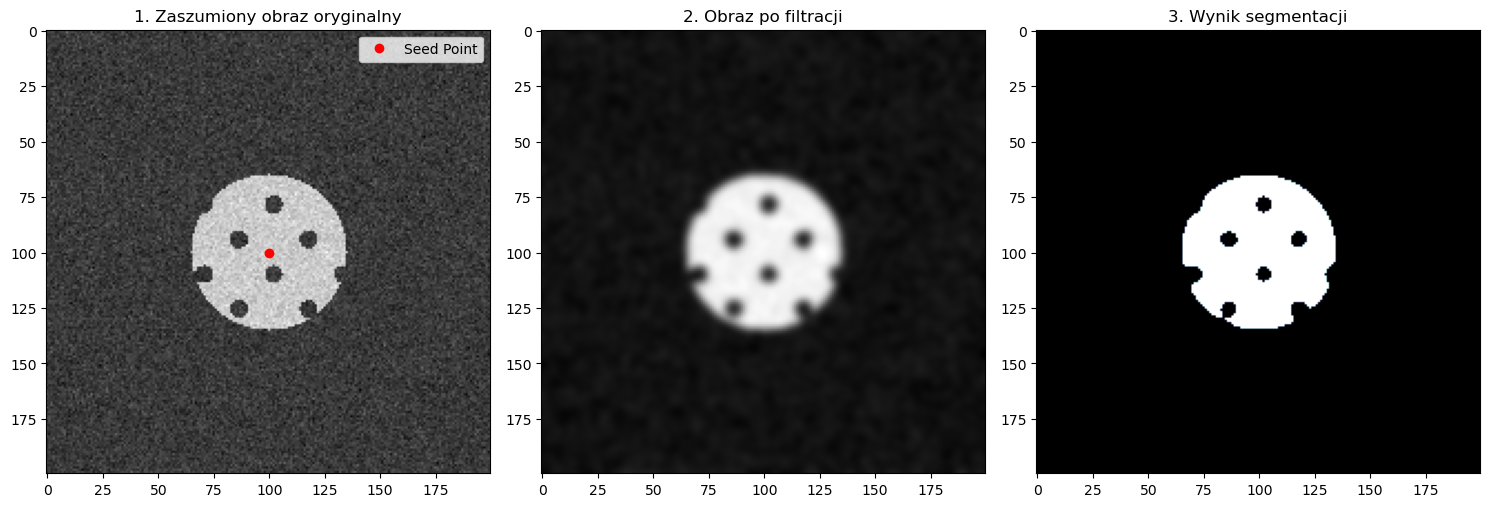

In [13]:
# Generowanie obrazu guza
np.random.seed(42)
img_size = (200, 200)
base_tissue = np.full(img_size, 0.2)

y_grid, x_grid = np.ogrid[:img_size[0], :img_size[1]]
tumor_mask = (x_grid - 100)**2 + (y_grid - 100)**2 <= 35**2
tumor_mask &= (np.sin(x_grid / 5) * np.cos(y_grid / 5)) > -0.7

synthetic_ct = base_tissue.copy()
synthetic_ct[tumor_mask] = 0.7 

# Dodajemy szum
noise = np.random.normal(0, 0.05, img_size)
synthetic_ct = np.clip(synthetic_ct + noise, 0, 1)

# -----------------------------------------------------
# ROZWIĄZANIE ZADANIA
# -----------------------------------------------------

# 1. Przefiltrowanie 'synthetic_ct', żeby usunąć szum. 
# Zastosowanie filtru Gaussa z wartością sigma=2 ładnie wygładza 
# pojedyncze zaszumione piksele, zapobiegając "wyciekowi" (leakage) algorytmu.
filtered_ct = filters.gaussian(synthetic_ct, sigma=2.0)

# 2. Ustalenie punktu początkowego (seed_point) wewnątrz guza.
# Skoro w kodzie wyżej generowaliśmy guza od środka obrazka 200x200 
# (przy użyciu x_grid - 100, y_grid - 100), to współrzędne (100, 100) są idealne.
seed_point = (100, 100)  

# 3. Dobór odpowiedniego progu odchylenia.
# Jasność guza wynosi około 0.7, a otaczającego go tła (tkanki) 0.2. 
# Różnica jasności wynosi więc około 0.5. Próg na poziomie 0.25 sprawi, 
# że maska ładnie obejmie całego guza, ale kategorycznie zatrzyma się na ciemniejszym tle.
threshold_val = 0.25  

# Uruchomienie algorytmu
tumor_seg = region_growing(filtered_ct, seed_point, threshold_val)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(synthetic_ct, cmap='gray')
axes[0].plot(seed_point[1], seed_point[0], 'ro', label='Seed Point')
axes[0].legend()
axes[0].set_title('1. Zaszumiony obraz oryginalny')
axes[1].imshow(filtered_ct, cmap='gray')
axes[1].set_title('2. Obraz po filtracji')
axes[2].imshow(tumor_seg, cmap='bone')
axes[2].set_title('3. Wynik segmentacji')
plt.tight_layout()
plt.show()

### Zadanie 4: Analiza ilościowa kształtu (Morfometria)

Użyjemy funkcji `measure.label()` do etykietowania wygenerowanej maski oraz `measure.regionprops()`, aby wyodrębnić informacje geometryczne o wyciętym obiekcie.

Wzór na **Współczynnik okrągłości (Circularity):**
$$ C = \frac{4 \cdot \pi \cdot A}{P^2} $$
Gdzie $A$ to pole powierzchni (area), a $P$ to obwód (perimeter).
Kształty bliskie idealnemu kołu mają ten wskaźnik bliski 1. Im kształt bardziej poszarpany i nieregularny, tym wynik jest niższy.

--- WYNIKI MORFOMETRII ---
Pole powierzchni (Area): 3501.0 px
Obwód (Perimeter): 370.54 px
Współczynnik okrągłości (Circularity): 0.3204


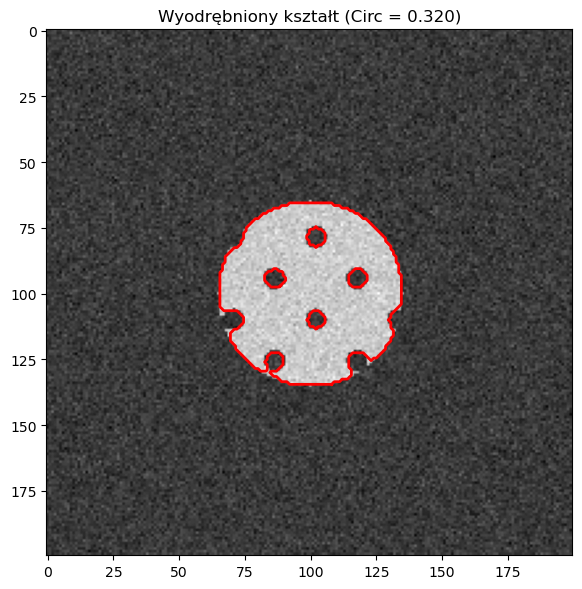

In [16]:
labeled_mask = measure.label(tumor_seg)
props = measure.regionprops(labeled_mask)

if props:
    region = props[0]
    
    # Rozwiązanie TODO 1: Pobranie pola powierzchni i obwodu ze zmiennej 'region'
    area = region.area 
    perimeter = region.perimeter
    
    # Rozwiązanie TODO 2: Obliczenie współczynnika okrągłości (zabezpieczone)
    # Wzór: C = (4 * pi * Area) / Perimeter^2
    if perimeter > 0:
        circularity = (4 * np.pi * area) / (perimeter ** 2)
    else:
        circularity = 0

    print("--- WYNIKI MORFOMETRII ---")
    print(f"Pole powierzchni (Area): {area} px")
    print(f"Obwód (Perimeter): {perimeter:.2f} px")
    print(f"Współczynnik okrągłości (Circularity): {circularity:.4f}")

    # Wizualizacja: Nakładanie konturu na zdjęcie
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(synthetic_ct, cmap='gray')
    contours = measure.find_contours(tumor_seg, 0.5)
    for contour in contours:
        ax.plot(contour[:, 1], contour[:, 0], linewidth=2, color='red')
    ax.set_title(f"Wyodrębniony kształt (Circ = {circularity:.3f})")
    plt.tight_layout()
    plt.show()
else:
    print("Nie wykryto żadnego obszaru!")